## Problem Statement

### Context

AllLife Bank is a US bank that has a growing customer base. The majority of these customers are liability customers (depositors) with varying sizes of deposits. The number of customers who are also borrowers (asset customers) is quite small, and the bank is interested in expanding this base rapidly to bring in more loan business and in the process, earn more through the interest on loans. In particular, the management wants to explore ways of converting its liability customers to personal loan customers (while retaining them as depositors).

A campaign that the bank ran last year for liability customers showed a healthy conversion rate of over 9% success. This has encouraged the retail marketing department to devise campaigns with better target marketing to increase the success ratio.

You as a Data scientist at AllLife bank have to build a model that will help the marketing department to identify the potential customers who have a higher probability of purchasing the loan.

### Objective

To predict whether a liability customer will buy personal loans, to understand which customer attributes are most significant in driving purchases, and identify which segment of customers to target more.

### Data Dictionary
* `ID`: Customer ID
* `Age`: Customer’s age in completed years
* `Experience`: #years of professional experience
* `Income`: Annual income of the customer (in thousand dollars)
* `ZIP Code`: Home Address ZIP code.
* `Family`: the Family size of the customer
* `CCAvg`: Average spending on credit cards per month (in thousand dollars)
* `Education`: Education Level. 1: Undergrad; 2: Graduate;3: Advanced/Professional
* `Mortgage`: Value of house mortgage if any. (in thousand dollars)
* `Personal_Loan`: Did this customer accept the personal loan offered in the last campaign? (0: No, 1: Yes)
* `Securities_Account`: Does the customer have securities account with the bank? (0: No, 1: Yes)
* `CD_Account`: Does the customer have a certificate of deposit (CD) account with the bank? (0: No, 1: Yes)
* `Online`: Do customers use internet banking facilities? (0: No, 1: Yes)
* `CreditCard`: Does the customer use a credit card issued by any other Bank (excluding All life Bank)? (0: No, 1: Yes)

## Importing necessary libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==1.25.2 pandas==1.5.3 matplotlib==3.7.1 seaborn==0.13.1 scikit-learn==1.2.2 sklearn-pandas==2.2.0 -q --user

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 42.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


**Note**:

1. After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab), write the relevant code for the project from the next cell, and run all cells sequentially from the next cell.

2. On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [ ]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Library to split data into train and test
from sklearn.model_selection import train_test_split

# To build model for prediction
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# To get diferent metric scores
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
)

# to suppress warnings
import warnings
warnings.filterwarnings("ignore")

## Loading the dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
LoanModelling = pd.read_csv("/content/drive/MyDrive/Great Learning/Project 2 Personal Loan Campaign/Loan_Modelling.csv")

In [ ]:
# copying data to another variable to avoid any changes to original data
data = LoanModelling.copy()

## Data Overview

* Observations
* Sanity checks

In [ ]:
data.head() #displaying first rows of the dataset

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [ ]:
data.sample(n=10, random_state=1) #viewing a sample of the data (10 rows)

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
2764,2765,31,5,84,91320,1,2.9,3,105,0,0,0,0,1
4767,4768,35,9,45,90639,3,0.9,1,101,0,1,0,0,0
3814,3815,34,9,35,94304,3,1.3,1,0,0,0,0,0,0
3499,3500,49,23,114,94550,1,0.3,1,286,0,0,0,1,0
2735,2736,36,12,70,92131,3,2.6,2,165,0,0,0,1,0
3922,3923,31,4,20,95616,4,1.5,2,0,0,0,0,1,0
2701,2702,50,26,55,94305,1,1.6,2,0,0,0,0,1,0
1179,1180,36,11,98,90291,3,1.2,3,0,0,1,0,0,1
932,933,51,27,112,94720,3,1.8,2,0,0,1,1,1,1
792,793,41,16,98,93117,1,4.0,3,0,0,0,0,0,1


Observations:
* There don't appear to be any missing values.

In [ ]:
data.shape #checking shape of the data

(5000, 14)

Observations:
* There are 5000 rows and 14 columns in this dataset.



In [ ]:
data.info() #checking the datatypes for the columns of the dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIPCode             5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal_Loan       5000 non-null   int64  
 10  Securities_Account  5000 non-null   int64  
 11  CD_Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


Observations:
*  All the columns are numerical.
*  The column *CCAvg* is a float.
*  It seems there are no missing values.

In [ ]:
data.describe().T #checking the statistical summary of the dataset

,count,mean,std,min,25%,50%,75%,max
ID,5000.0,2500.500000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Age,5000.0,45.338400,11.463166,23.0,35.00,45.0,55.00,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.00,20.0,30.00,43.0
Income,5000.0,73.774200,46.033729,8.0,39.00,64.0,98.00,224.0
ZIPCode,5000.0,93169.257000,1759.455086,90005.0,91911.00,93437.0,94608.00,96651.0
Family,5000.0,2.396400,1.147663,1.0,1.00,2.0,3.00,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.70,1.5,2.50,10.0
Education,5000.0,1.881000,0.839869,1.0,1.00,2.0,3.00,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.00,0.0,101.00,635.0
Personal_Loan,5000.0,0.096000,0.294621,0.0,0.00,0.0,0.00,1.0


Observations:

* The mean of the age of the customers is around 45 years old.
* Since the minimum age is 23 years old and the maximum is 67 years old, the customers are mostly middle aged adults.
* The mean experience of the customers is of 20 years.
* However, the minimum experience being -3 is suspicious, so there is likely a data error which needs to be analized and fixed.
* Since the family mean is of 2.4 members and the maximum members in a family is 4, it is observed that the costumers of this bank have relatively small families.
* The zip code data is not meaningful as numerical beacuse it should be treated categorically.
* Since the mean of education is 1.88, it indicates that most customers have undergaduate or graduate levels of education, while fewer have and advanced or professional level.
* The income mean is of 73K dollars.
* The income data seems to be right skewed.
* The average spending on credit cards seems to be about 1.93K dollars per month. However, the maximum spending is of 10K dollars, which indicates a small number of customers with very high spending.
* Mortgage is heavily right skewed. It is interesting because over 50% of the customers appear to have no mortgage.

In [ ]:
data.isnull().sum() #checking for null values

,0
ID,0
Age,0
Experience,0
Income,0
ZIPCode,0
Family,0
CCAvg,0
Education,0
Mortgage,0
Personal_Loan,0


Observations:
* There are no missing values

In [ ]:
data.duplicated().sum() #checking for duplicate values

np.int64(0)

Observations:
* There are no duplicate values in this dataset.

## Exploratory Data Analysis.

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions**:

1. What is the distribution of mortgage attribute? Are there any noticeable patterns or outliers in the distribution?
2. How many customers have credit cards?
3. What are the attributes that have a strong correlation with the target attribute (personal loan)?
4. How does a customer's interest in purchasing a loan vary with their age?
5. How does a customer's interest in purchasing a loan vary with their education?

####Question 1. What is the distribution of mortgage attribute? Are there any noticeable patterns or outliers in the distribution?

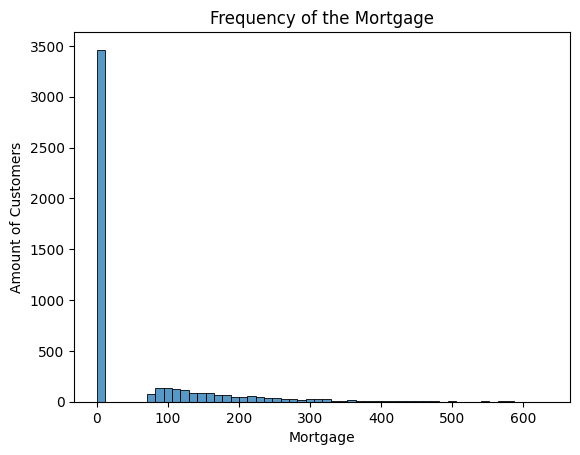

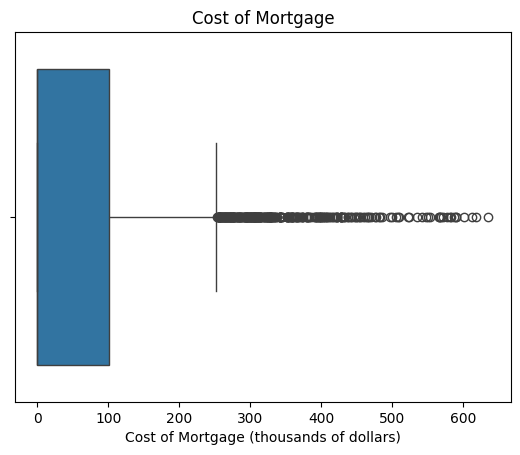

In [ ]:
# Code for distribution of mortgage
# Histogram
sns.histplot(data=data, x='Mortgage')
plt.xlabel("Mortgage")
plt.ylabel("Amount of Customers")
plt.title("Frequency of the Mortgage")
plt.show()

# Boxplot
sns.boxplot(data=data, x='Mortgage')
plt.xlabel("Cost of Mortgage (thousands of dollars)")
plt.title("Cost of Mortgage")
plt.show()

Observations:
* At least 50% of customers do not have a mortgage.
* A small amount of customers have a high mortgage.
* This distribution is strongly right-skewed.
* There are many outliers where customers have very high mortgage values.





####Question 2. How many customers have credit cards?



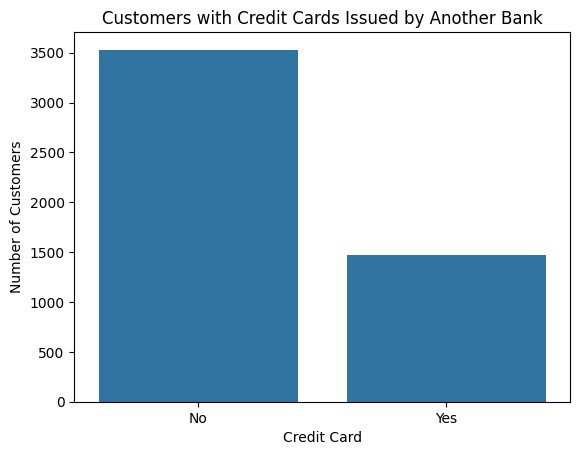

In [ ]:
#Code to determine number of customers with and without credit cards form other banks
sns.countplot(x=data['CreditCard'].map({0: 'No', 1: 'Yes'}))
plt.xlabel("Credit Card")
plt.ylabel("Number of Customers")
plt.title("Customers with Credit Cards Issued by Another Bank")
plt.show()


Observations:
* Around 3500 costumers do not have a credit card issued by any other bank, while approximately 1500 costumers do.
* However, the dataset does not include information indicating whether customers hold a credit card issued by AllLife Bank. Therefore, it is not possible to determine if customers who do not have credit cards with other banks do possess one with AllLife.
* The AllLife bank could offer first-time promotions and highlight benefits (like rewards or low interest) to encourage customers without credit cards to aquire one.

####Question 3. What are the attributes that have a strong correlation with the target attribute (personal loan)?

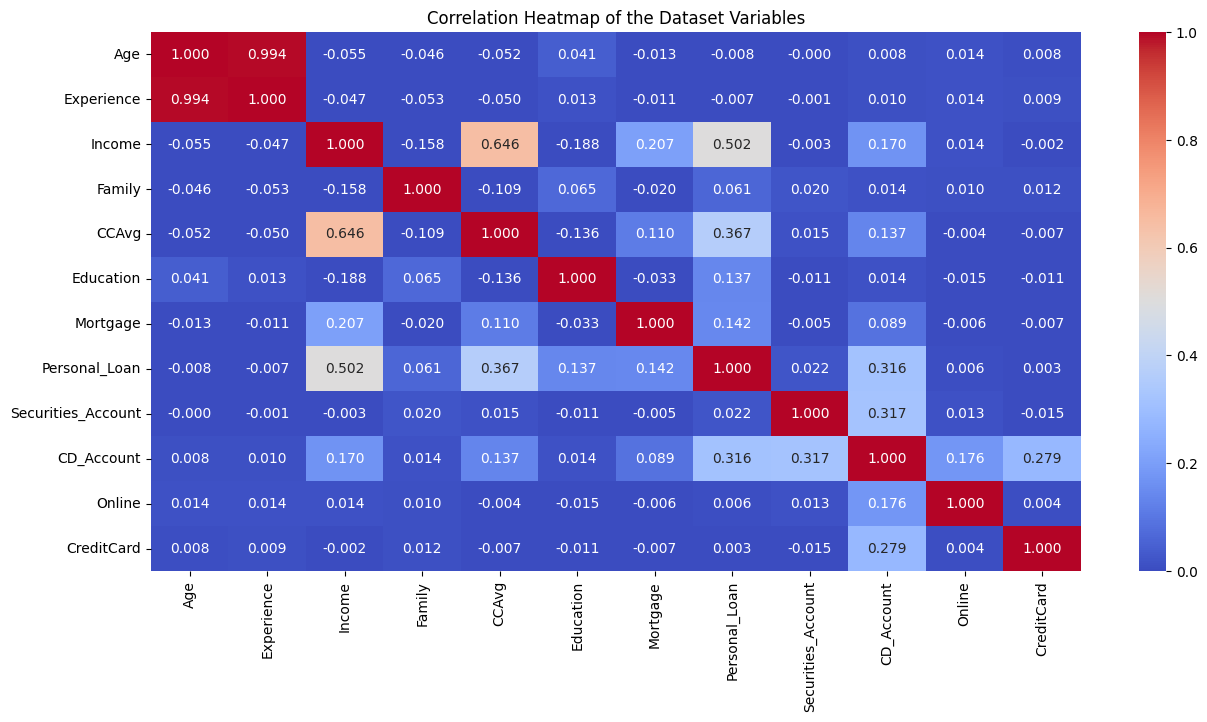

In [ ]:
# Eliminating columns not needed
data_clean = data.drop(columns=['ID', 'ZIPCode']) #eliminitating the columns

# Check for correlation among the variables
corr = data_clean.corr(numeric_only = True)

# Plot the heatmap
plt.figure(figsize=(15, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-0,
    vmax=1
)
plt.title("Correlation Heatmap of the Dataset Variables")
plt.show()

Observations:
* The strongest correlation with Personal Loan is the one with Income. It indicate a moderate to slightly strong positive correlation in which, the higher the income of the cutomer, the more likely they were to accept the loan offered in the last campaign.
* The next highest correlation is with the variable CCAvg (average spending on credit cards per month). It is also a slightly less strong positive correlation, in which customers who spend more on their credit cards were also more likely to accept the loan.
* The last moderate positve correlation is with CD_Account (if the customer has a certificate of deposit (CD) account with the bank). In this case customers with CD accounts were more likely to accept the loan offer.
* The correlations with Education and Mortgage are positive, but weak. The rest of the correlations with the other variables can be ignored.

Other important correlations:
* It is important to add that Age and Experience have an extremely high positive correlation indicating that this relationship is multicollinear (they carry almost the same information). It might be best to eliminate one of these from the dataset when modeling.
* Income and CCAvg have a moderately strong positive correlation. This shows that people who earn more tend to spend more.
* Between CD_Account and Securites_Account there is a moderate positive correlation. This means the customers who have a CD account are more likely to also have a securities account.
* CreditCard and CD_Account have a slightly lower positive correlation which means that financially active customers might be more likely to have multiple credit cards.


####Question 4. How does a customer's interest in purchasing a loan vary with their age?

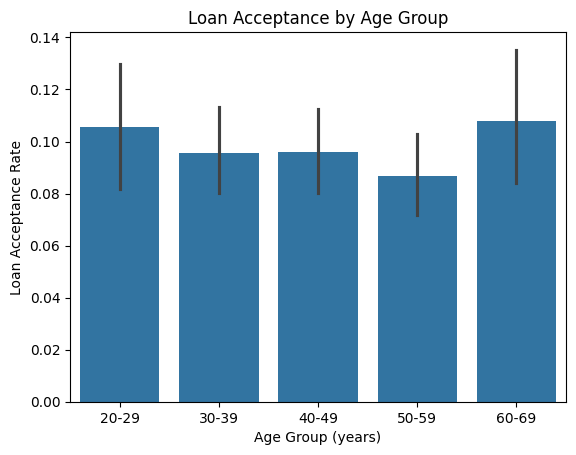

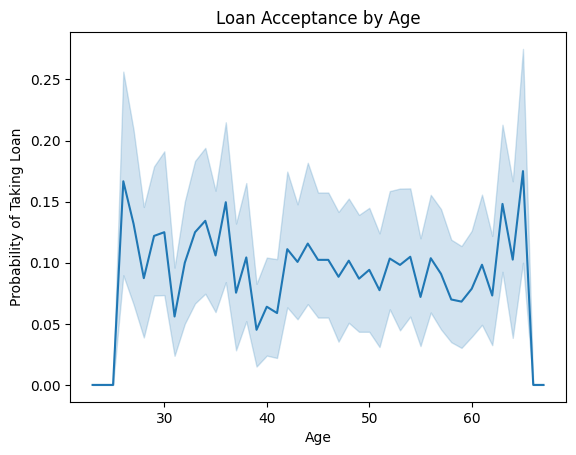

In [ ]:
# Defining the bins and labels to create the age groups
bins = [20, 30, 40, 50, 60, 70]
labels = ['20-29', '30-39', '40-49', '50-59', '60-69']

data_clean['AgeGroup'] = pd.cut(data_clean['Age'], bins=bins, labels=labels)

# Plotting the bar chart
sns.barplot(x='AgeGroup', y='Personal_Loan', data=data_clean)

plt.xlabel("Age Group (years)")
plt.ylabel("Loan Acceptance Rate")
plt.title("Loan Acceptance by Age Group")
plt.show()

sns.lineplot(x='Age', y='Personal_Loan', data=data)

plt.ylabel("Probability of Taking Loan")
plt.title("Loan Acceptance by Age")
plt.show()

Observations:
* The relationship between age and loan acceptance is weak. The grouped bar chart shows that loan acceptance rates remain relatively constant across age groups. Therefore, age does not appear to significantly influence a customer’s likelihood of accepting a personal loan.
* In customers between the ages of 20 to 29 years old, around 10.5% accepted the loan offered. In customers between the ages of 60 to 69, approximately 11% accepted the loan.
* The spike in older ages may be do to a sampling noise and not a real trend.

####Question 5. How does a customer's interest in purchasing a loan vary with their education?

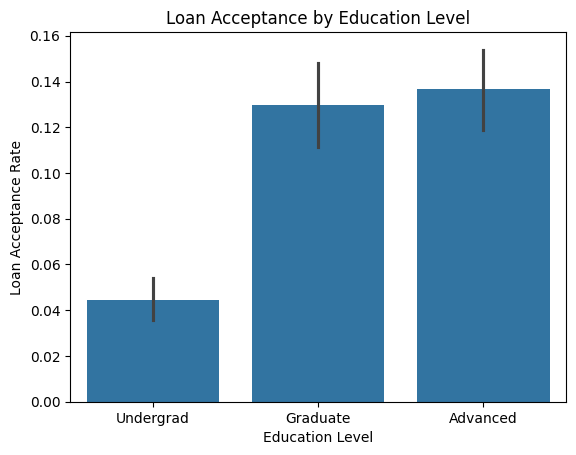

In [ ]:
# Code for the barplot
sns.barplot(
    x=data['Education'].map({1: 'Undergrad', 2: 'Graduate', 3: 'Advanced'}),
    y='Personal_Loan',
    data=data
)

plt.xlabel("Education Level")
plt.ylabel("Loan Acceptance Rate")
plt.title("Loan Acceptance by Education Level")
plt.show()

Observations:
* Loan acceptance tends to increase with higher levels of education. Customers with advanced or professional education exhibit the highest loan acceptance rates, followed by graduates, while undergraduate customers show the lowest rates.
* The main change is observed when a customer is an undegraduate versus when they are a graduate because it significantly increases the likelihood of accepting the loan.
* However, the correlation showed that these differences are moderate, indicating that education has some influence on loan interest but is not a strong predictor compared to other variables like income.

####Univariate Analysis

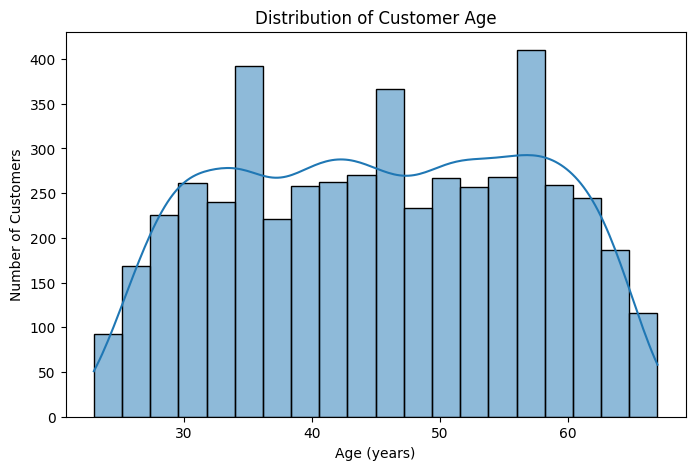

In [157]:
# Histogram of frequency of ages of customers
plt.figure(figsize=(8,5))

sns.histplot(data['Age'], bins=20, kde=True)

plt.title('Distribution of Customer Age')
plt.xlabel('Age (years)')
plt.ylabel('Number of Customers')

plt.show()

Observations:
* Age is fairly evenly distibuted.
* The dataset includes customers across a wide range of ages without heavy concentration in one group.
* The bank’s customer base is primarily composed of working-age adults.


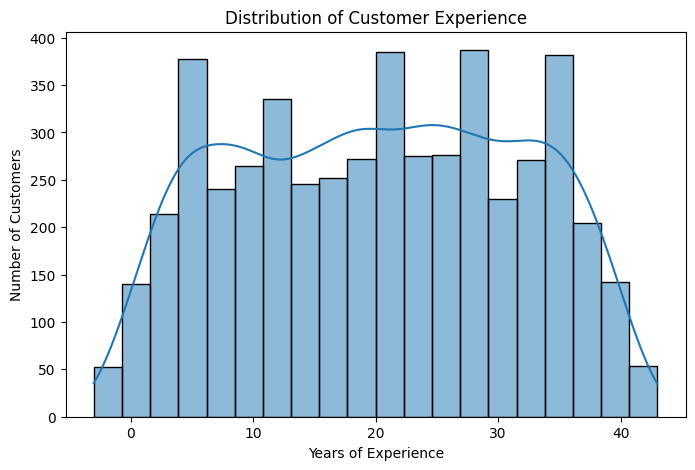

In [158]:
#  Histogram of frequency of customers and their years of experience
plt.figure(figsize=(8,5))

sns.histplot(data['Experience'], bins=20, kde=True)

plt.title('Distribution of Customer Experience')
plt.xlabel('Years of Experience')
plt.ylabel('Number of Customers')

plt.show()

Observations:
* There is a presence of negative values, which has to be a data error.
* There is a wide distribution of experience.
* The histogram is fairly spread out.
* Since the higher density of experience is between 10-35 years, it could be said that most customers are in mid-career stages.
* The shape of this histogram is very similar to the Age variable one.

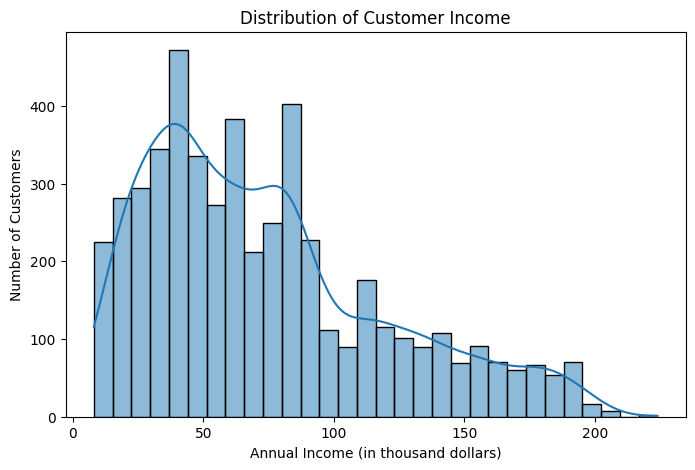

In [160]:
# Histogram of the income earned by the customers
plt.figure(figsize=(8,5))

sns.histplot(data['Income'], bins=30, kde=True)

plt.title('Distribution of Customer Income')
plt.xlabel('Annual Income (in thousand dollars)')
plt.ylabel('Number of Customers')

plt.show()

Observations:
* There is a right-skewed distribution of this data.
* Most customers have a low to medium income with a select few ones having high incomes. This is typical in real-world financial data.
* There is a presence of high income outliers.

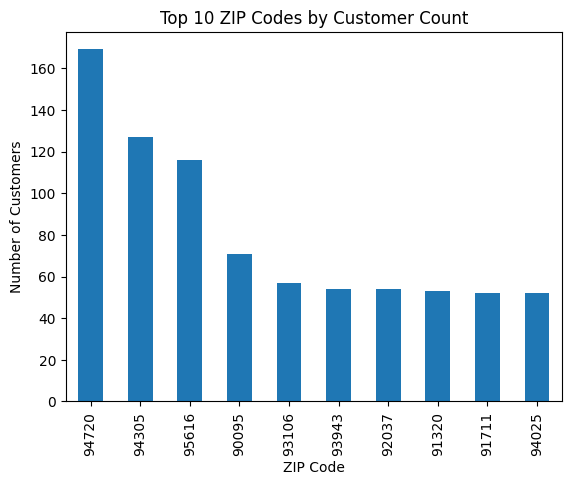

In [163]:
# Frequency of customers in the top 10 zip codes
data['ZIPCode'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 ZIP Codes by Customer Count')
plt.xlabel('ZIP Code')
plt.ylabel('Number of Customers')
plt.show()

Observations:
* Customers are not evenly distributed geographically.
* Certain regions have higher customer representation.

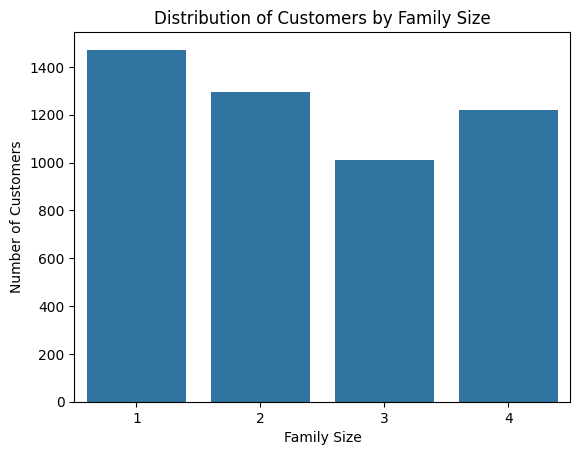

In [164]:
# Family size of the customers
sns.countplot(x='Family', data=data)
plt.title('Distribution of Customers by Family Size')
plt.xlabel('Family Size')
plt.ylabel('Number of Customers')

plt.show()

Observations:
* Most customers belong to small households.
* Medium-sized families (3 members) are less represented.
* The distribution is fairly balanced:

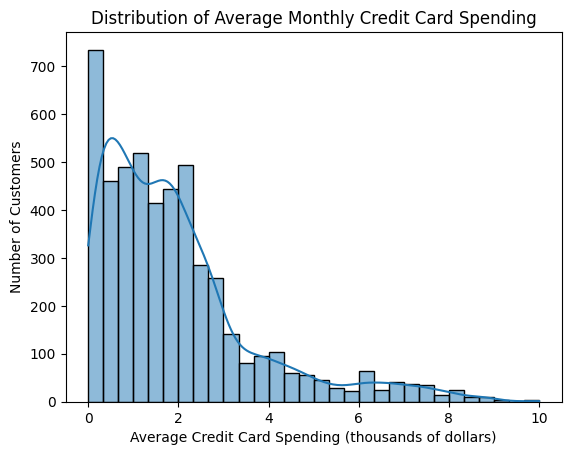

In [166]:
# Histogram of the avarage monthly credit card spending for the customers
sns.histplot(data['CCAvg'], bins=30, kde=True)
plt.title('Distribution of Average Monthly Credit Card Spending')
plt.xlabel('Average Credit Card Spending (thousands of dollars)')
plt.ylabel('Number of Customers')

plt.show()

Observations:
* This graph is right-skewed which shows that most customers spend low to moderate amounts, meaning that they have low credit card usage.
* There is a wide spread of variability which indicates that the customers have very different spending habbits.

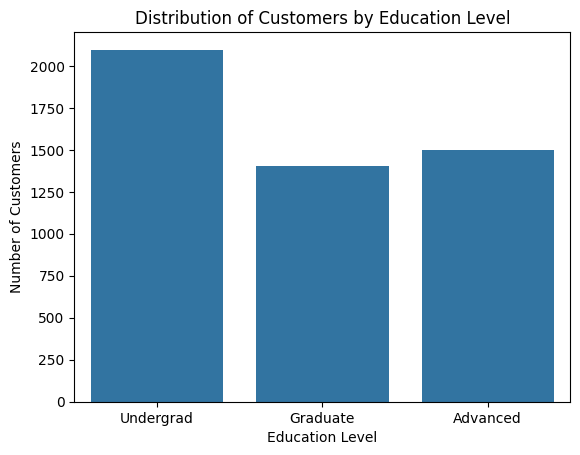

In [167]:
# Customers per education level
sns.countplot(x=data['Education'].map({
    1: 'Undergrad',
    2: 'Graduate',
    3: 'Advanced'
}))
plt.title('Distribution of Customers by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Number of Customers')

plt.show()

Observations:
* A large portion of the bank’s customers have undergraduate-level education.
* There appears to be no major bias in education representation.

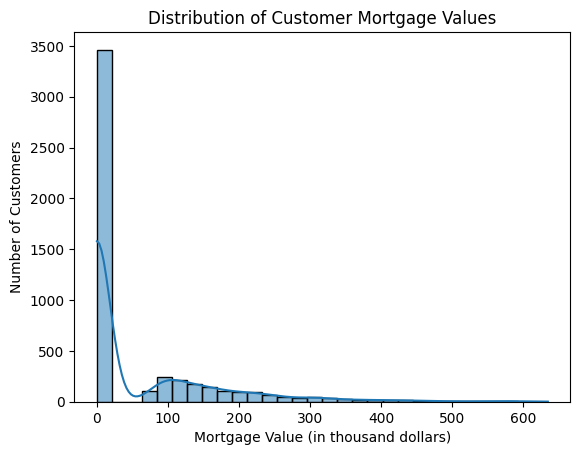

In [168]:
# Histogram  mortgage customers have
sns.histplot(data['Mortgage'], bins=30, kde=True)
plt.title('Distribution of Customer Mortgage Values')
plt.xlabel('Mortgage Value (in thousand dollars)')
plt.ylabel('Number of Customers')

plt.show()

Observations:
* Mortgage values are highly positively skewed.
* A large portion of customers have no mortgage at all, while a smaller group has moderate to high mortgage values.

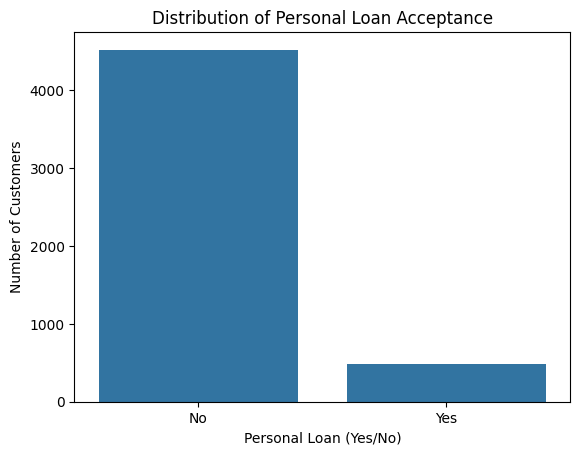

In [170]:
# Customers and their personal loan
sns.countplot(x=data['Personal_Loan'].map({0: 'No', 1: 'Yes'}))
plt.title('Distribution of Personal Loan Acceptance')
plt.xlabel('Personal Loan (Yes/No)')
plt.ylabel('Number of Customers')

plt.show()

Observations:
* Very few customers accept personal loans, which means that accepting a loan is not common behavior.
* This is an imbalanced dataset.
* The business value is in the customers that do accept a loan.

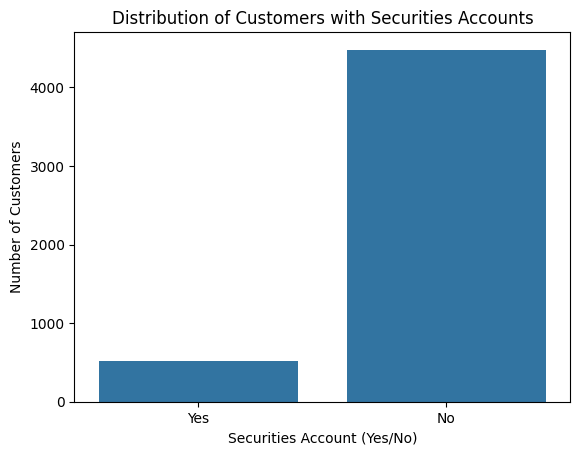

In [172]:
# Distribution of customers and their securities account
sns.countplot(x=data['Securities_Account'].map({0: 'No', 1: 'Yes'}))
plt.title('Distribution of Customers with Securities Accounts')
plt.xlabel('Securities Account (Yes/No)')
plt.ylabel('Number of Customers')

plt.show()

Observations:
* Most customers do not have a securities account.
* Customers with securities accounts are likely to be more financially knowledgeable and/or more engaged with banking products.

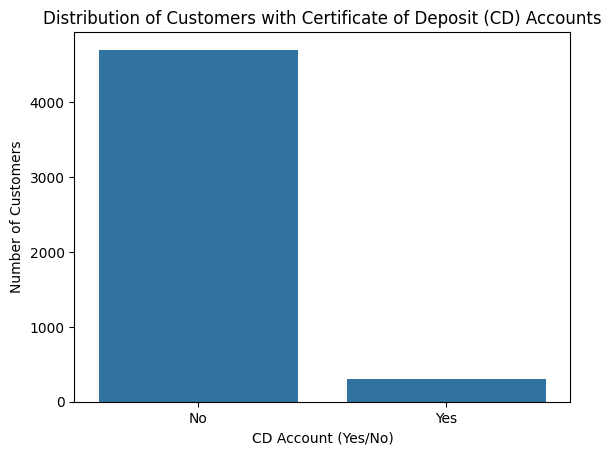

In [173]:
# Distribution of customers and their Certificate of Deposit
sns.countplot(x=data['CD_Account'].map({0: 'No', 1: 'Yes'}))
plt.title('Distribution of Customers with Certificate of Deposit (CD) Accounts')
plt.xlabel('CD Account (Yes/No)')
plt.ylabel('Number of Customers')

plt.show()

Observations:
* Certificate of Deposit (CD) accounts are rare among customers.
* The bank might want to prioritize CD account holders for loan offers since these customers might already trust the bank.

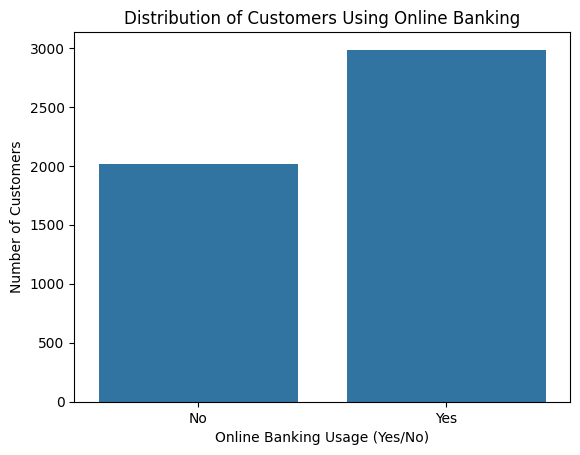

In [174]:
# Distibution of customers that use the online platform
sns.countplot(x=data['Online'].map({0: 'No', 1: 'Yes'}))
plt.title('Distribution of Customers Using Online Banking')
plt.xlabel('Online Banking Usage (Yes/No)')
plt.ylabel('Number of Customers')

plt.show()

Observations:
* Most customers are digitally engaged.
* Online banking is fairly common.
* For customers who use the online banking system more, the bank could send
email campaigns, app notifications or digital ads.
* For offline users, the bank could use marketing strategies like phone calls or in-branch offers.

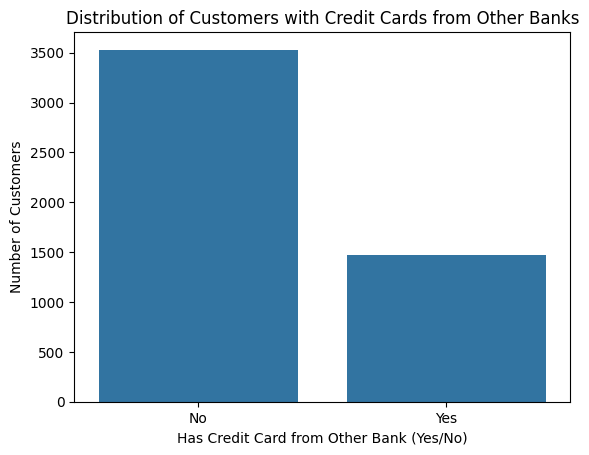

In [175]:
# Distribution of customers that have credit cards from other banks
sns.countplot(x=data['CreditCard'].map({0: 'No', 1: 'Yes'}))
plt.title('Distribution of Customers with Credit Cards from Other Banks')
plt.xlabel('Has Credit Card from Other Bank (Yes/No)')
plt.ylabel('Number of Customers')

plt.show()

Observations:
* Most customers rely primarily on this bank (AllLife).
* The bank has strong customer retention, but there is still significant competition with other banks.
* Customers without other bank cards might be more loyal and easier to target.
* Meanwhile, customers with other credit cards might be more comfortable with credit.

####Multivariate Analysis

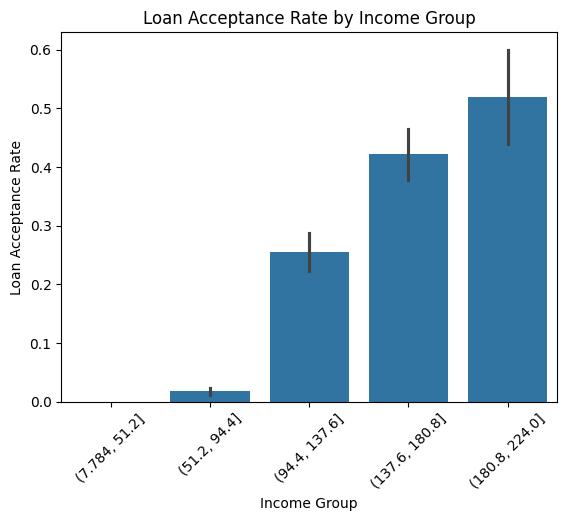

In [177]:
# Income vs Personal_Loan
data_temp = data.copy()
data_temp['Income_Group'] = pd.cut(data_temp['Income'], bins=5) #Creating income bins

sns.barplot(x='Income_Group', y='Personal_Loan', data=data_temp)

plt.title('Loan Acceptance Rate by Income Group')
plt.xlabel('Income Group (thousands of dollars)')
plt.ylabel('Loan Acceptance Rate')
plt.xticks(rotation=45)

plt.show()

Observations:
* As income increases, the loan acceptance rate increases significantly.
* This shows that income has a strong and direct impact on loan acceptance.
* Low-income customers are very unlikely to accept loans. On the contrary, high-income customers are prime loan candidates.

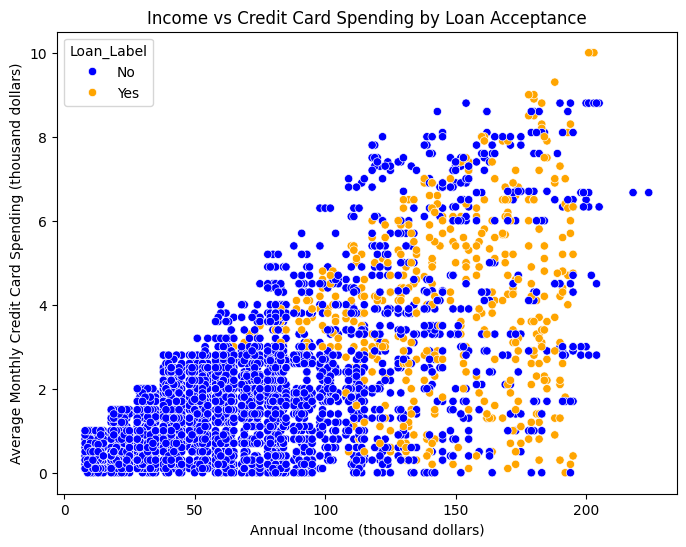

In [184]:
#Income vs Credit Card Spending by Loan Acceptance
# Create proper categorical labels
data['Loan_Label'] = data['Personal_Loan'].map({0: 'No', 1: 'Yes'})

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=data,
    x='Income',
    y='CCAvg',
    hue='Loan_Label',
    palette={'No': 'blue', 'Yes': 'orange'}   # <-- FORCE colors
)

plt.xlabel("Annual Income (thousand dollars)")
plt.ylabel("Average Monthly Credit Card Spending (thousand dollars)")
plt.title("Income vs Credit Card Spending by Loan Acceptance")

plt.show()

Observations:
* Higher-income customers tend to spend more on credit cards.
* Customers with low income and low spending are very unlikely to accept loans.

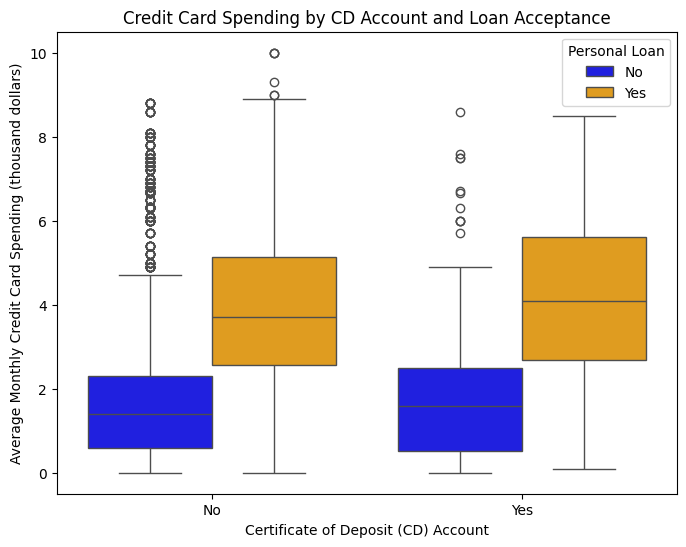

In [186]:
# Credit Card Spending by CD Account and Loan Acceptance
data['CD_Label'] = data['CD_Account'].map({0: 'No', 1: 'Yes'})
data['Loan_Label'] = data['Personal_Loan'].map({0: 'No', 1: 'Yes'})

plt.figure(figsize=(8,6))

sns.boxplot(
    data=data,
    x='CD_Label',
    y='CCAvg',
    hue='Loan_Label',
    palette={'No': 'blue', 'Yes': 'orange'}
)

# Axis labels
plt.xlabel("Certificate of Deposit (CD) Account")
plt.ylabel("Average Monthly Credit Card Spending (thousand dollars)")

# Title
plt.title("Credit Card Spending by CD Account and Loan Acceptance")

# Legend
plt.legend(title="Personal Loan")

plt.show()

Observations:
* Customers with CD accounts are more financially active and tend to spend more.
* Credit card spending is a strong discriminator of loan acceptance.
* Spending is important independently of CD account.
* The bank should target customers with high credit card spending, especially those with CD accounts.

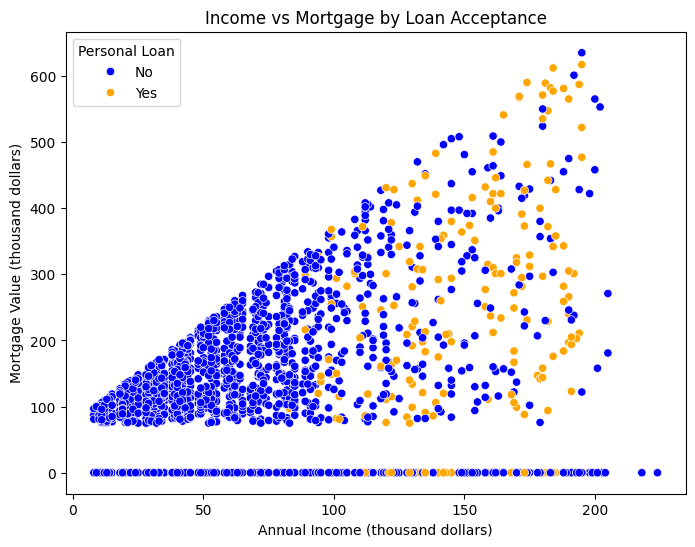

In [187]:
#Income vs Mortgage by Loan Acceptance
data['Loan_Label'] = data['Personal_Loan'].map({0: 'No', 1: 'Yes'})

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=data,
    x='Income',
    y='Mortgage',
    hue='Loan_Label',
    palette={'No': 'blue', 'Yes': 'orange'}
)

# Axis labels
plt.xlabel("Annual Income (thousand dollars)")
plt.ylabel("Mortgage Value (thousand dollars)")

# Title
plt.title("Income vs Mortgage by Loan Acceptance")

# Legend
plt.legend(title="Personal Loan")

plt.show()

Observations:
* Income remains the primary driver of loan acceptance.
* Mortgage does not clearly distinguish between loan vs no-loan customers.
* A large portion of customers do not have mortgages yet they still may or may not accept loans.
* Having a high mortgage does not necessarily mean the customer will accept another loan.

## Data Preprocessing

* Missing value treatment
* Feature engineering (if needed)
* Outlier detection and treatment (if needed)
* Preparing data for modeling
* Any other preprocessing steps (if needed)

In [ ]:
data.isnull().sum() # checking for missing values

,0
ID,0
Age,0
Experience,0
Income,0
ZIPCode,0
Family,0
CCAvg,0
Education,0
Mortgage,0
Personal_Loan,0


Observations:
* There are no missing values in any columns

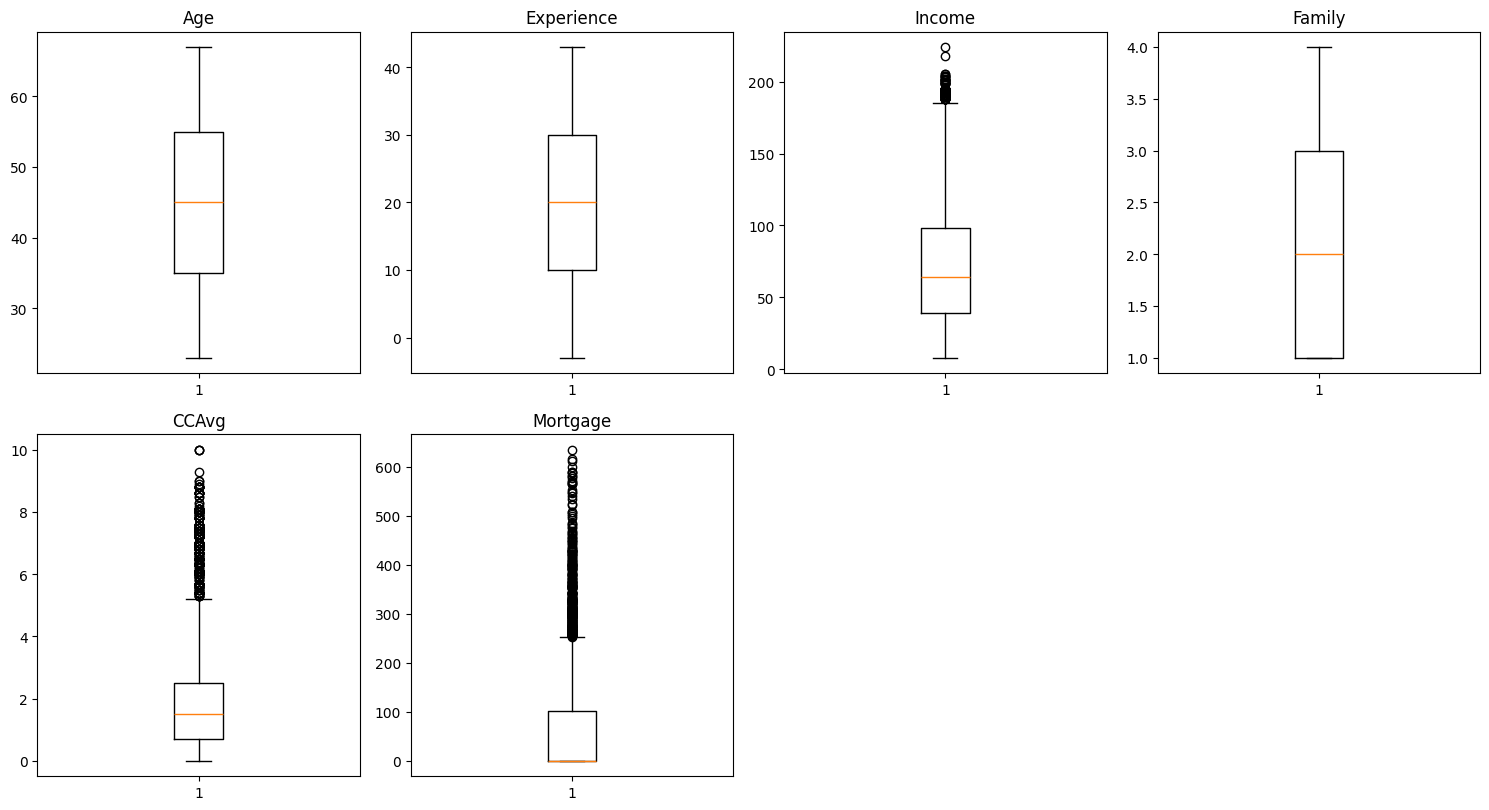

In [ ]:
#Detecting outliers using boxplot
binary_cols = ['Personal_Loan', 'Securities_Account', 'CD_Account', 'Online', 'CreditCard'] #determining bivariate variables
data_numeric = data.drop(columns=['ID', 'ZIPCode', 'Education'] + binary_cols) #also removing the categorical columns and the ID column

plt.figure(figsize=(15, 12))

for i, variable in enumerate(data_numeric):
    plt.subplot(3, 4, i + 1)
    plt.boxplot(data_numeric[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

In [ ]:
#Numerical way to detect and count outliers
Q1 = data.select_dtypes(include=["float64", "int64"]).quantile(0.25)
Q3 = data.select_dtypes(include=["float64", "int64"]).quantile(0.75)

IQR = Q3 - Q1  # Inter Quantile Range (75th perentile - 25th percentile)

lower = (
    Q1 - 1.5 * IQR
)  # Finding lower and upper bounds for all values. All values outside these bounds are outliers
upper = Q3 + 1.5 * IQR

(
    (data.select_dtypes(include=["float64", "int64"]) < lower)
    | (data.select_dtypes(include=["float64", "int64"]) > upper)
).sum() / len(data) * 100

,0
ID,0.00
Age,0.00
Experience,0.00
Income,1.92
ZIPCode,0.00
Family,0.00
CCAvg,6.48
Education,0.00
Mortgage,5.82
Personal_Loan,9.60


Observations:
* Variables like Income, CCAvg and Mortgage have strong outliers.
* Variables like Personal_Loan and CD_Account are bivariate, which means that the boxplot doesn´t give me useful information about them. Similarly, the Zip Code and Education variables are categorical, so they won't yield meaningful results.

In [ ]:
#Preparing the data before modeling
# defining the dependent and independent variables
X = data.drop(["Personal_Loan", "Experience", "ID"], axis=1)  #dropping the column Experience because it introduces multicollinearity
Y = data["Personal_Loan"]

X = pd.get_dummies(X, columns=["ZIPCode", "Education"], drop_first=True) #Encoding these columns

X = X.astype(float)

# Splitting data in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.30, random_state=1
)

In [ ]:
print("Shape of Training set : ", X_train.shape)
print("Shape of test set : ", X_test.shape)
print("Percentage of classes in training set:")
print(y_train.value_counts(normalize=True))
print("Percentage of classes in test set:")
print(y_test.value_counts(normalize=True))

Shape of Training set :  (3500, 477)
Shape of test set :  (1500, 477)
Percentage of classes in training set:
Personal_Loan
0    0.905429
1    0.094571
Name: proportion, dtype: float64
Percentage of classes in test set:
Personal_Loan
0    0.900667
1    0.099333
Name: proportion, dtype: float64


Observations:
* The difference of class distribution between the training and test sets is very little, which means that this split is balanced and the model will be fairly evaluated.
* Since there are 477 features, there is a risk of overfitting.

In [ ]:
#Now preparing the data and dropping the ZIP code column
X = data.drop(["Personal_Loan", "Experience", "ID", "ZIPCode"], axis=1)
Y = data["Personal_Loan"]
X = pd.get_dummies(X, columns=["Education"], drop_first=True) #Encoding this column

X = X.astype(float)

# Splitting data in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.30, random_state=1
)

In [ ]:
print("Shape of Training set : ", X_train.shape)
print("Shape of test set : ", X_test.shape)
print("Percentage of classes in training set:")
print(y_train.value_counts(normalize=True))
print("Percentage of classes in test set:")
print(y_test.value_counts(normalize=True))

Shape of Training set :  (3500, 11)
Shape of test set :  (1500, 11)
Percentage of classes in training set:
Personal_Loan
0    0.905429
1    0.094571
Name: proportion, dtype: float64
Percentage of classes in test set:
Personal_Loan
0    0.900667
1    0.099333
Name: proportion, dtype: float64


Observations:
* The difference of class distribution between the training and test sets is very little, which means that this split is balanced and the model will be fairly evaluated.
* Now there are only 11 features, which reduces the risk of overfitting and the model is easier to train.

## Model Building

### Model Evaluation Criterion

In [ ]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )

    return df_perf

In [ ]:
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

Observations:
* The F1 score provides a balance between precision and recall, offering an overall measure of model performance.
* Recall indicates how effectively the model identifies customers who are likely to accept a loan.
* Precision reflects how many of the predicted loan acceptances are actually correct, helping assess false positives.
* Due to class imbalance, accuracy alone is not a reliable metric for evaluating the model.

### Model Building

In [ ]:
#Decision Tree Model
model = DecisionTreeClassifier(criterion="gini", random_state=1)
model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=1)

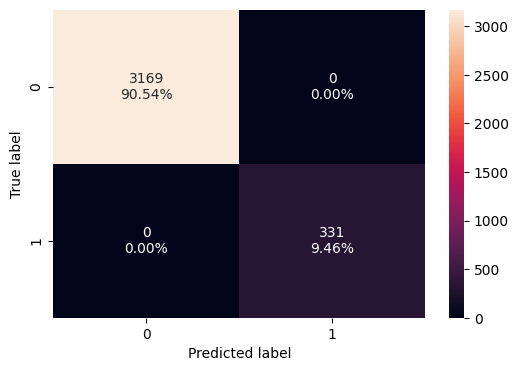

In [ ]:
#Checking the model performance on the training data
confusion_matrix_sklearn(model, X_train, y_train)

In [ ]:
#Checking the model evaluation criterion on the training data
decision_tree_perf_train = model_performance_classification_sklearn(
    model, X_train, y_train
)
decision_tree_perf_train

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


Observations:
* Model is able to perfectly classify all the data points on the training set.
* There are zero errors on the training set, each sample has been classified correctly.
* This generally leads to overfitting of the model as the Decision Tree will perform well on the training set but will fail to replicate the performance on the test set. This is because the model memorized the training data.

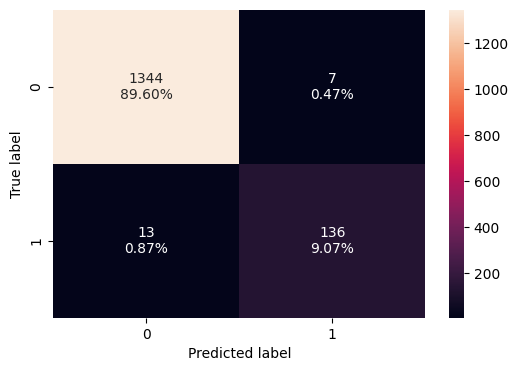

In [ ]:
#Checking the model performance on the test data
confusion_matrix_sklearn(model, X_test, y_test)

In [ ]:
#Checking the model evaluation criterion on the test data
decision_tree_perf_test = model_performance_classification_sklearn(
    model, X_test, y_test
)
decision_tree_default_perf_test

,Accuracy,Recall,Precision,F1
0,0.986667,0.912752,0.951049,0.931507


Observations:
* The model still performs well, but it may not generalize perfectly to new data, which confirms overfitting.
* The recall shows that the model correctly identified 91% of customers who accept loans.
* However, there were 13 false negatives (customers who would accept a loan were missed).

In [ ]:
#Visualizing the Decision Tree
feature_names = list(X_train.columns)
print(feature_names)

['Age', 'Income', 'Family', 'CCAvg', 'Mortgage', 'Securities_Account', 'CD_Account', 'Online', 'CreditCard', 'Education_2', 'Education_3']


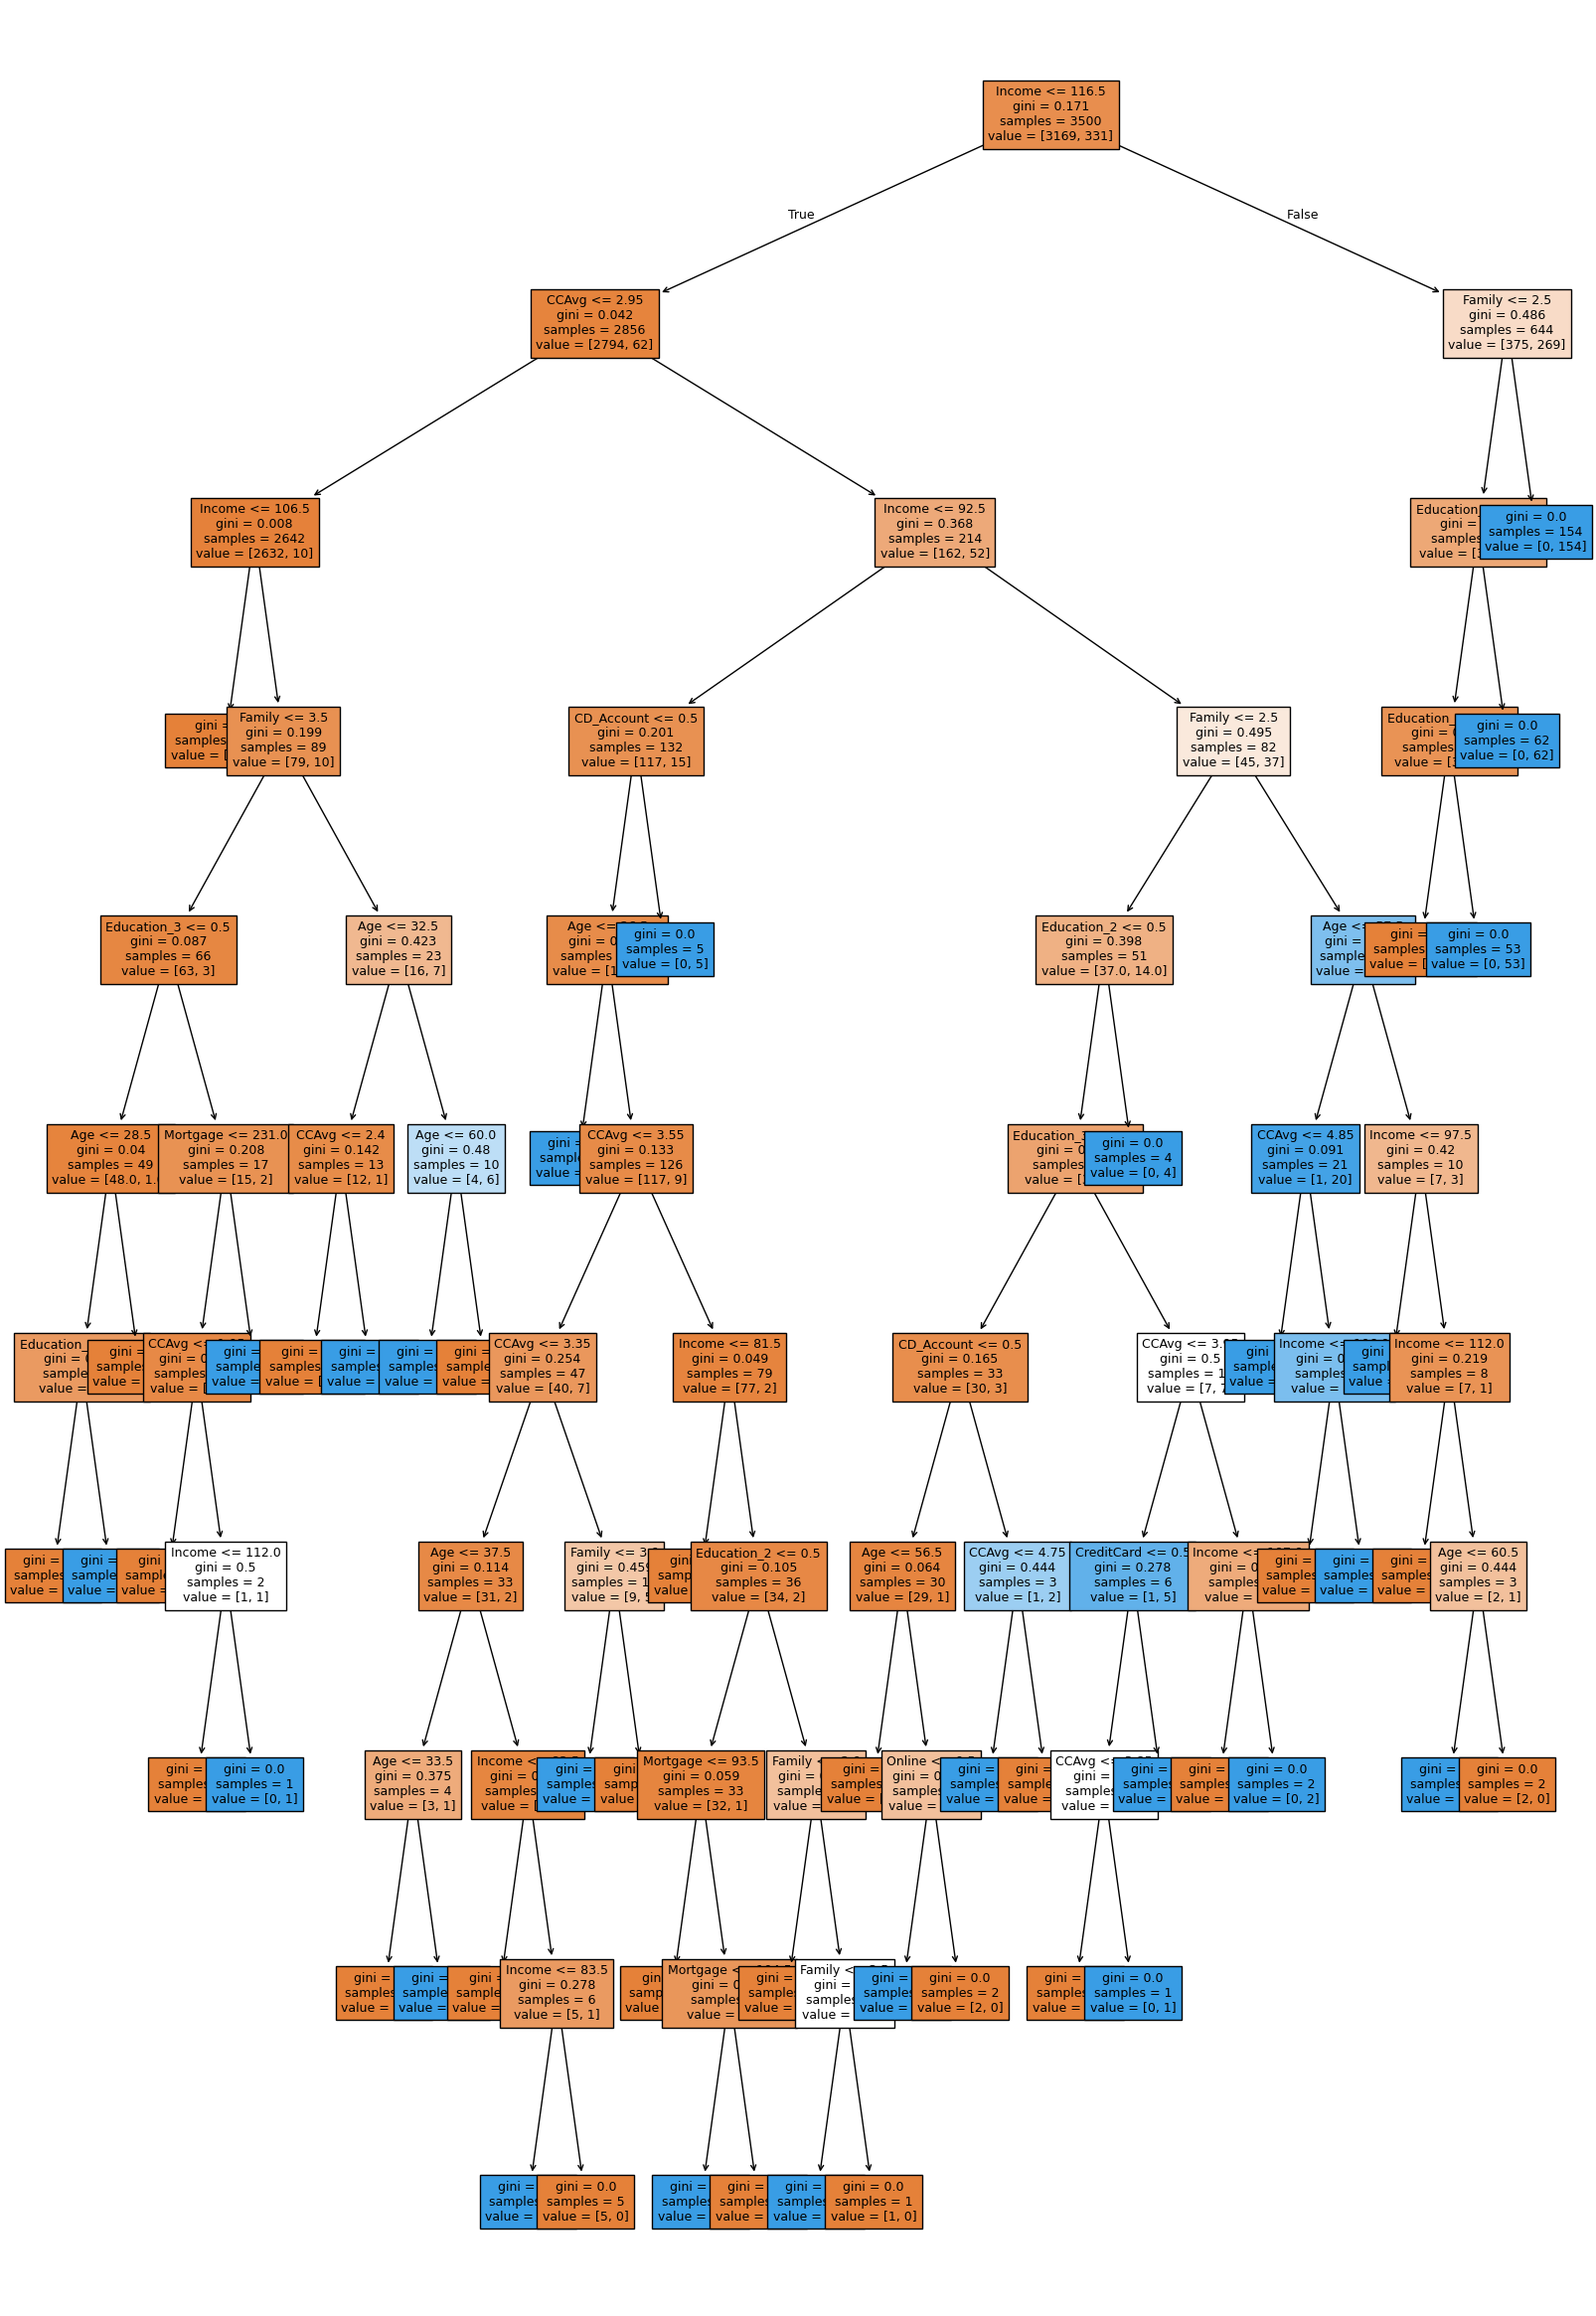

In [ ]:
plt.figure(figsize=(20, 30))
out = tree.plot_tree(
    model,
    feature_names=feature_names,
    filled=True,
    fontsize=9,
    node_ids=False,
    class_names=None,
)
# below code will add arrows to the decision tree split if they are missing
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor("black")
        arrow.set_linewidth(1)
plt.show()

In [ ]:
# Text report showing the rules of a decision tree

print(tree.export_text(model, feature_names=feature_names, show_weights=True))

|--- Income <= 116.50
|   |--- CCAvg <= 2.95
|   |   |--- Income <= 106.50
|   |   |   |--- weights: [2553.00, 0.00] class: 0
|   |   |--- Income >  106.50
|   |   |   |--- Family <= 3.50
|   |   |   |   |--- Education_3 <= 0.50
|   |   |   |   |   |--- Age <= 28.50
|   |   |   |   |   |   |--- Education_2 <= 0.50
|   |   |   |   |   |   |   |--- weights: [5.00, 0.00] class: 0
|   |   |   |   |   |   |--- Education_2 >  0.50
|   |   |   |   |   |   |   |--- weights: [0.00, 1.00] class: 1
|   |   |   |   |   |--- Age >  28.50
|   |   |   |   |   |   |--- weights: [43.00, 0.00] class: 0
|   |   |   |   |--- Education_3 >  0.50
|   |   |   |   |   |--- Mortgage <= 231.00
|   |   |   |   |   |   |--- CCAvg <= 1.95
|   |   |   |   |   |   |   |--- weights: [14.00, 0.00] class: 0
|   |   |   |   |   |   |--- CCAvg >  1.95
|   |   |   |   |   |   |   |--- Income <= 112.00
|   |   |   |   |   |   |   |   |--- weights: [1.00, 0.00] class: 0
|   |   |   |   |   |   |   |--- Income >  112.00
|   

In [ ]:
#Importance of features in the tree building
print(
    pd.DataFrame(
        model.feature_importances_, columns=["Imp"], index=X_train.columns
    ).sort_values(by="Imp", ascending=False)
)

                         Imp
Income              0.315198
Family              0.259811
Education_2         0.166192
Education_3         0.144605
CCAvg               0.055184
Age                 0.032404
CD_Account          0.017273
Mortgage            0.005996
Online              0.002224
CreditCard          0.001112
Securities_Account  0.000000


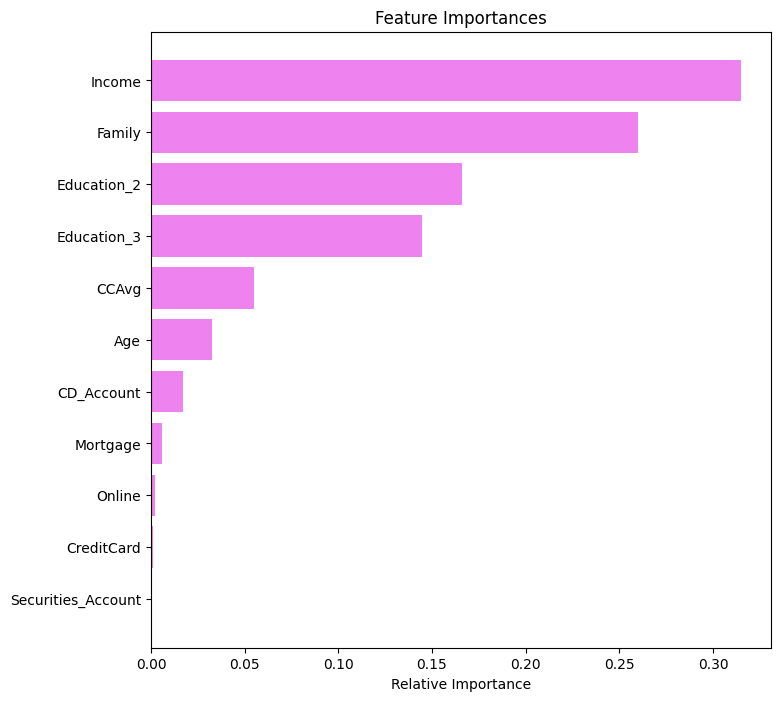

In [ ]:
#Importance of features in the tree building
importances = model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 8))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

Observations:
* In the tree, the income, the number of family members and the type of education are the most important features in the acceptance of loans.
* The model perfectly classifies the training data.
* The model still performs very well on unseen data
* Although the model shows signs of overfitting, it generalizes well, maintaining high recall and precision on the test set.
* The model is efficient but could improve slightly in identifying all potential loan customers.
* The tree is overly complex, which contributes to overfitting.
* The Income is the strongest predictor.
* The model suggests that financial variables (Income, Spending) drive decisions.
* Demographics like Age and Family are less important.
* The customer engagement (CD Account) matters.

## Model Performance Improvement

####Pre-pruning

In [ ]:
# Define the parameters of the tree to iterate over
max_depth_values = np.arange(2, 7, 2)
max_leaf_nodes_values = [50, 75, 150, 250]
min_samples_split_values = [10, 30, 50, 70]

# Initialize variables to store the best model and its performance
best_estimator = None
best_score_diff = float('inf')
best_test_score = 0.0

# Iterate over all combinations of the specified parameter values
for max_depth in max_depth_values:
    for max_leaf_nodes in max_leaf_nodes_values:
        for min_samples_split in min_samples_split_values:

            # Initialize the tree with the current set of parameters
            estimator = DecisionTreeClassifier(
                max_depth=max_depth,
                max_leaf_nodes=max_leaf_nodes,
                min_samples_split=min_samples_split,
                class_weight='balanced',
                random_state=42
            )

            # Fit the model to the training data
            estimator.fit(X_train, y_train)

            # Make predictions on the training and test sets
            y_train_pred = estimator.predict(X_train)
            y_test_pred = estimator.predict(X_test)

            # Calculate recall scores for training and test sets
            train_recall_score = recall_score(y_train, y_train_pred)
            test_recall_score = recall_score(y_test, y_test_pred)

            # Calculate the absolute difference between training and test recall scores
            score_diff = abs(train_recall_score - test_recall_score)

            # Update the best estimator and best score if the current one has a smaller score difference
            if (score_diff < best_score_diff) & (test_recall_score > best_test_score):
                best_score_diff = score_diff
                best_test_score = test_recall_score
                best_estimator = estimator

# Print the best parameters
print("Best parameters found:")
print(f"Max depth: {best_estimator.max_depth}")
print(f"Max leaf nodes: {best_estimator.max_leaf_nodes}")
print(f"Min samples split: {best_estimator.min_samples_split}")
print(f"Best test recall score: {best_test_score}")

Best parameters found:
Max depth: 2
Max leaf nodes: 50
Min samples split: 10
Best test recall score: 1.0


In [ ]:
# Fit the best algorithm to the data.
estimator = best_estimator
estimator.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=np.int64(2),
                       max_leaf_nodes=50, min_samples_split=10,
                       random_state=42)

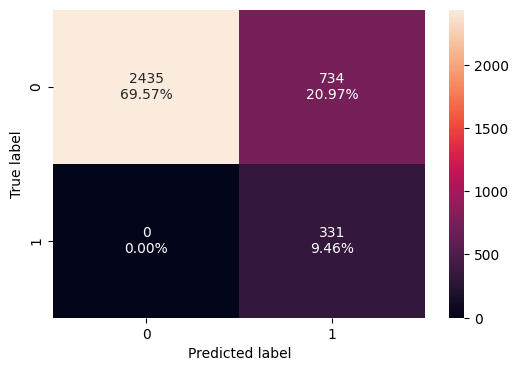

In [ ]:
#Checking the performance on the training data
confusion_matrix_sklearn(estimator, X_train, y_train)

In [ ]:
#Checking the model evaluation criterion on the training data
decision_tree_tune_perf_train = model_performance_classification_sklearn(estimator,  X_train, y_train)
decision_tree_tune_perf_train

,Accuracy,Recall,Precision,F1
0,0.790286,1.0,0.310798,0.474212


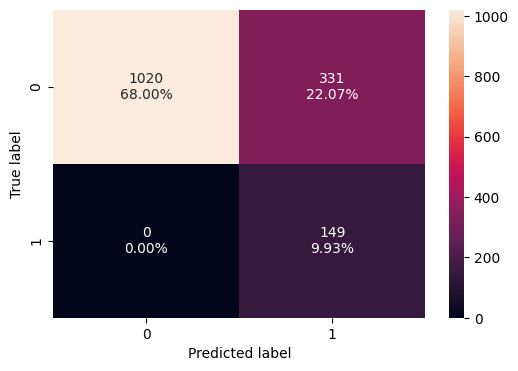

In [ ]:
#Checking the performance on the test data
confusion_matrix_sklearn(estimator, X_test, y_test)

In [ ]:
#Checking the model evaluation criterion on the test data
decision_tree_tune_perf_test = model_performance_classification_sklearn(estimator,  X_train, y_train)
decision_tree_tune_perf_test

,Accuracy,Recall,Precision,F1
0,0.790286,1.0,0.310798,0.474212


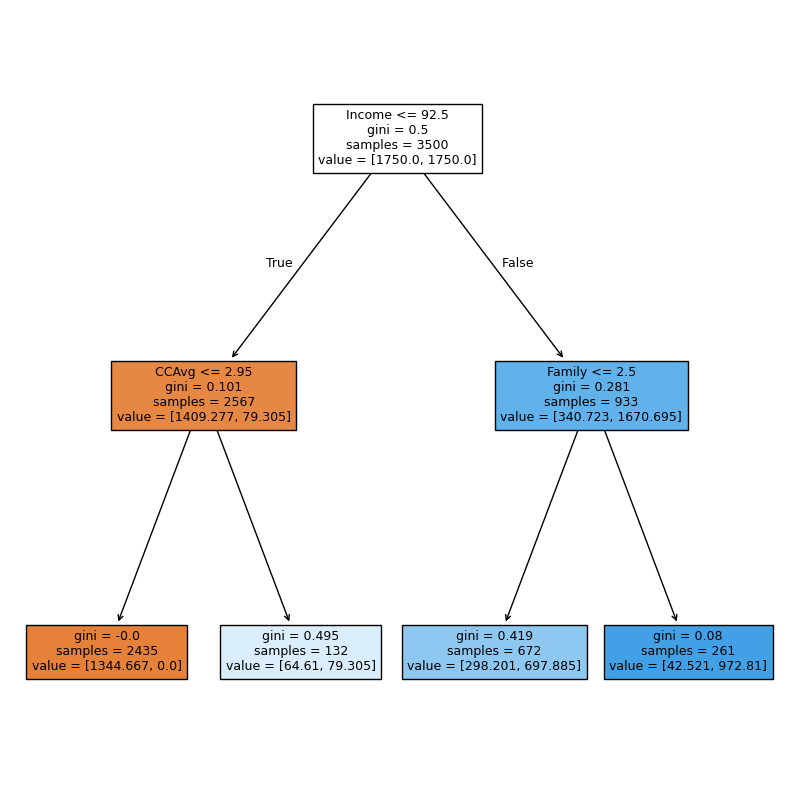

In [ ]:
#Visualizing the Decision Tree
plt.figure(figsize=(10, 10))
out = tree.plot_tree(
    estimator,
    feature_names=feature_names,
    filled=True,
    fontsize=9,
    node_ids=False,
    class_names=None,
)
# below code will add arrows to the decision tree split if they are missing
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor("black")
        arrow.set_linewidth(1)
plt.show()

In [ ]:
# Text report showing the rules of a decision tree

print(tree.export_text(estimator, feature_names=feature_names, show_weights=True))

|--- Income <= 92.50
|   |--- CCAvg <= 2.95
|   |   |--- weights: [1344.67, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- weights: [64.61, 79.31] class: 1
|--- Income >  92.50
|   |--- Family <= 2.50
|   |   |--- weights: [298.20, 697.89] class: 1
|   |--- Family >  2.50
|   |   |--- weights: [42.52, 972.81] class: 1



In [ ]:
# importance of features in the tree building
print(
    pd.DataFrame(
        estimator.feature_importances_, columns=["Imp"], index=X_train.columns
    ).sort_values(by="Imp", ascending=False)
)

                         Imp
Income              0.876529
CCAvg               0.066940
Family              0.056531
Age                 0.000000
Mortgage            0.000000
Securities_Account  0.000000
CD_Account          0.000000
Online              0.000000
CreditCard          0.000000
Education_2         0.000000
Education_3         0.000000


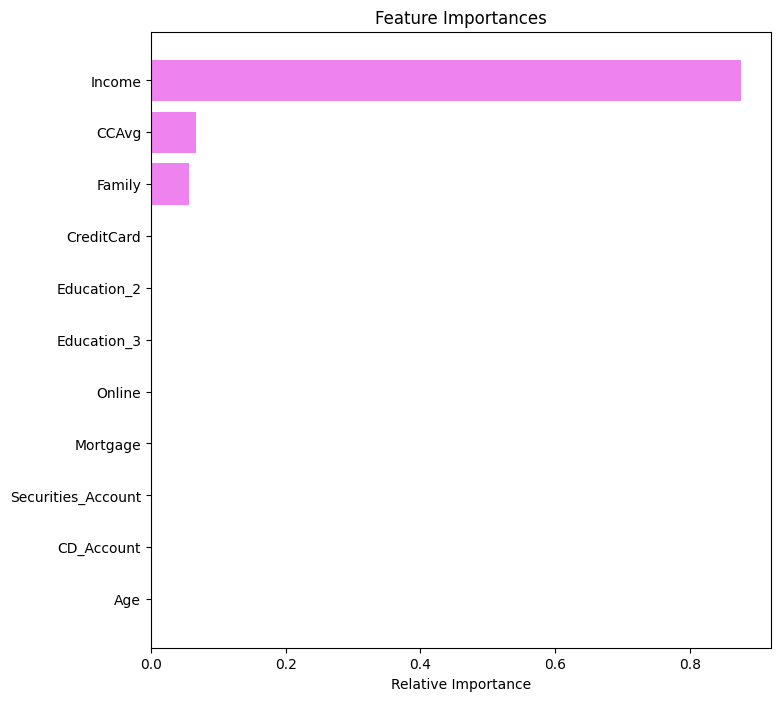

In [ ]:
importances = estimator.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 8))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

Observations:
*  In the tree, the income, the average spending on credit cards per month (in thousand dollars) and the number of family members are the only important features in the acceptance of loans.
* The pre-pruned model is much simpler than the original tree.
* The model finds all the customers that will accept loans, but it has a lot of false positives.
* The model does not show overfitting and is a stable model.
* Regardless, it is a poor model overall.
* It relies almost entirely on Income.
* If used, there could be a high marketing cost with low efficiency.

####Post-pruning

In [ ]:
clf = DecisionTreeClassifier(random_state=1)
path = clf.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

In [ ]:
pd.DataFrame(path)

,ccp_alphas,impurities
0,0.000000,0.000000
1,0.000186,0.001114
2,0.000238,0.001590
3,0.000250,0.002090
4,0.000268,0.002626
5,0.000268,0.003699
6,0.000272,0.004244
7,0.000275,0.005344
8,0.000276,0.005897
9,0.000381,0.006278


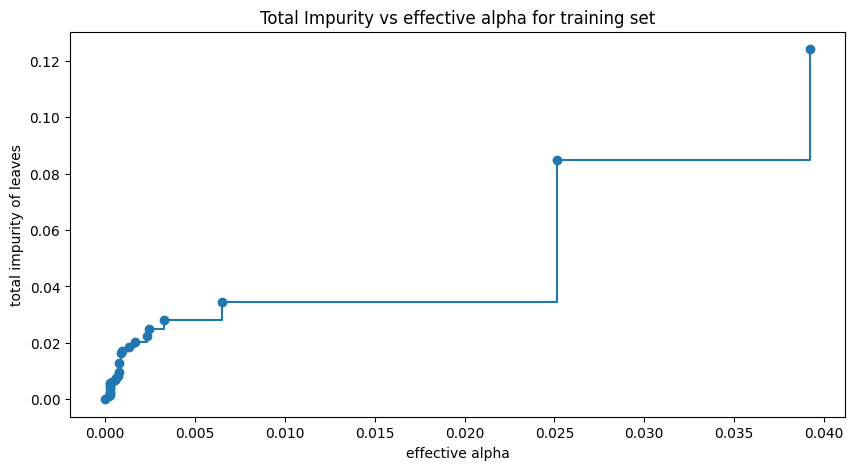

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set")
plt.show()

In [ ]:
#Training a decision tree using the effective alphas
clfs = []
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=1, ccp_alpha=ccp_alpha)
    clf.fit(X_train, y_train)
    clfs.append(clf)
print(
    "Number of nodes in the last tree is: {} with ccp_alpha: {}".format(
        clfs[-1].tree_.node_count, ccp_alphas[-1]
    )
)

Number of nodes in the last tree is: 1 with ccp_alpha: 0.04708834100596766


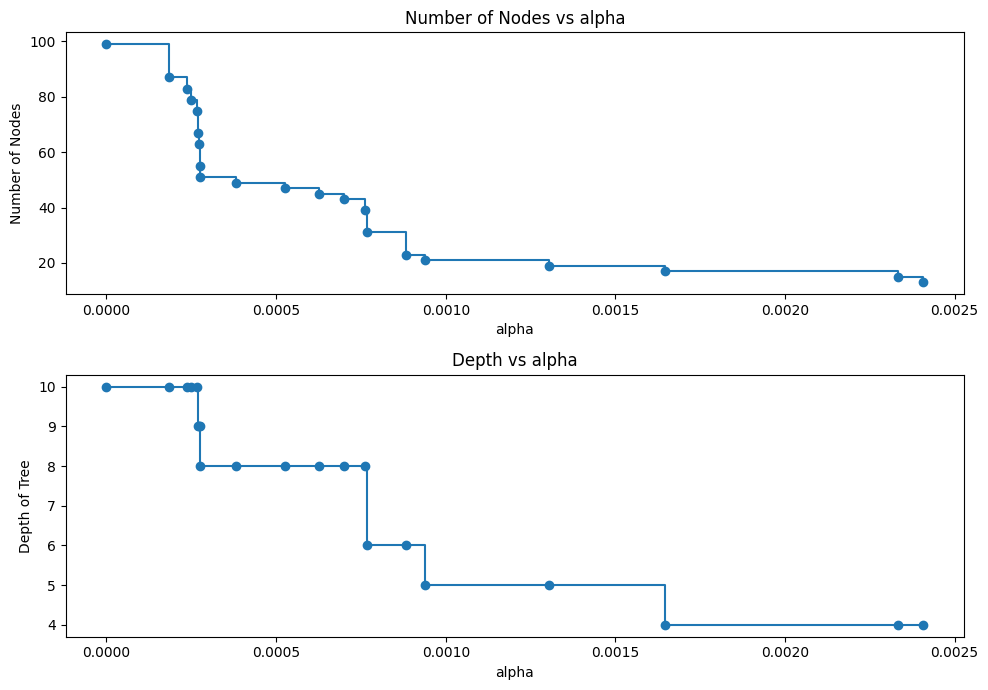

In [ ]:
clfs = clfs[:-1]
ccp_alphas = ccp_alphas[:-1]

node_counts = [clf.tree_.node_count for clf in clfs]
depth = [clf.tree_.max_depth for clf in clfs]
fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("Number of Nodes")
ax[0].set_title("Number of Nodes vs alpha")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("Depth of Tree")
ax[1].set_title("Depth vs alpha")
fig.tight_layout()

In [ ]:
#Recall vs alpha for training and testing sets
recall_train = []
for clf in clfs:
    pred_train = clf.predict(X_train)
    values_train = recall_score(y_train, pred_train)
    recall_train.append(values_train)

In [ ]:
recall_test = []
for clf in clfs:
    pred_test = clf.predict(X_test)
    values_test = recall_score(y_test, pred_test)
    recall_test.append(values_test)

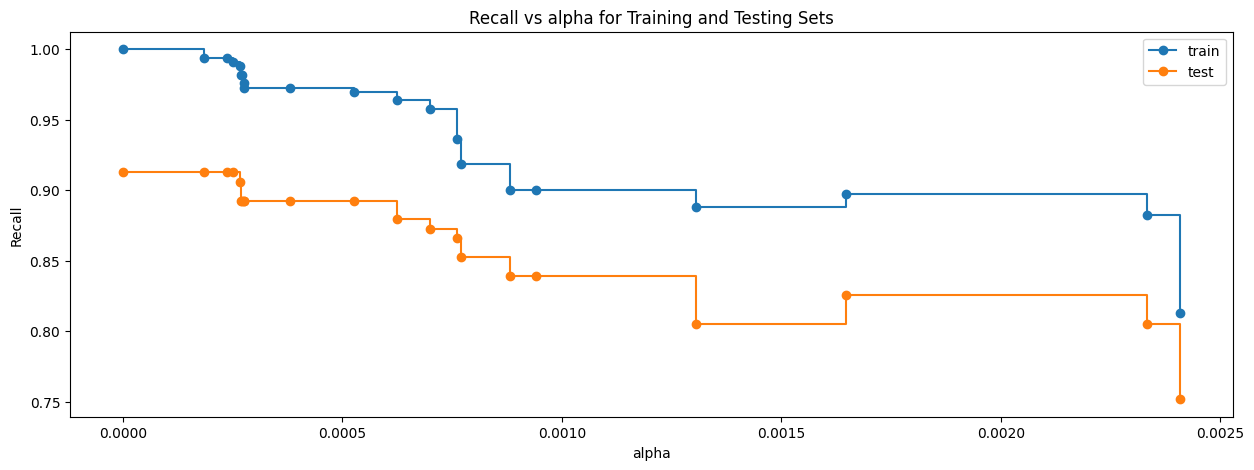

In [ ]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.set_xlabel("alpha")
ax.set_ylabel("Recall")
ax.set_title("Recall vs alpha for Training and Testing Sets")
ax.plot(ccp_alphas, recall_train, marker="o", label="train", drawstyle="steps-post")
ax.plot(ccp_alphas, recall_test, marker="o", label="test", drawstyle="steps-post")
ax.legend()
plt.show()

In [ ]:
index_best_model = np.argmax(recall_test)
best_model = clfs[index_best_model]
print(best_model)

DecisionTreeClassifier(ccp_alpha=np.float64(0.0), random_state=1)


In [ ]:
estimator_2 = DecisionTreeClassifier(
    ccp_alpha=0.0, class_weight={0: 0.15, 1: 0.85}, random_state=1
)
estimator_2.fit(X_train, y_train)

DecisionTreeClassifier(class_weight={0: 0.15, 1: 0.85}, random_state=1)

Observations:
* Train recall starts at 1.0 while test recall starts around 0.91. However, the test recall only decreases form there.
* This means that the model best performs when alpha equals 0. Therefore, pruning is not beneficial. Although the training was perfect in the first model, the test performance was already very good. Although the pruning reducess the overfitting, it also reduces the performance.
* It seems the original tree is the optimal one.

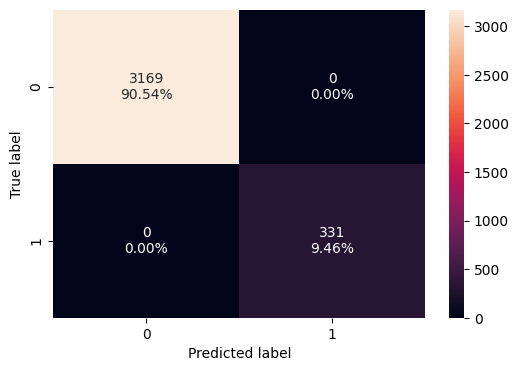

In [ ]:
#Checking the performance on the training data
confusion_matrix_sklearn(estimator_2, X_train, y_train)

In [ ]:
#Checking the model evaluation criterion on the training data
decision_tree_tune_post_train = model_performance_classification_sklearn(
    estimator_2, X_train, y_train
)
decision_tree_tune_post_train

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


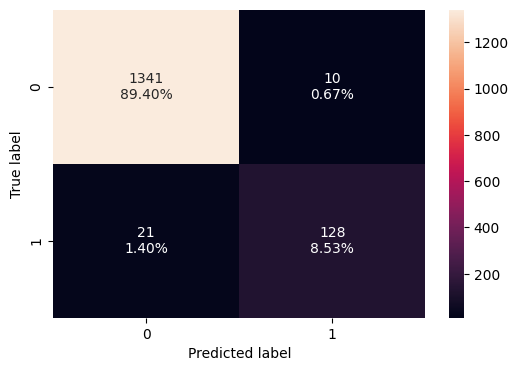

In [ ]:
#Checking the performance on the test data
confusion_matrix_sklearn(estimator_2, X_test, y_test)

In [ ]:
#Checking the model evaluation criterion on the test data
decision_tree_tune_post_test = model_performance_classification_sklearn(
    estimator_2, X_test, y_test
)
decision_tree_tune_post_test

,Accuracy,Recall,Precision,F1
0,0.979333,0.85906,0.927536,0.891986


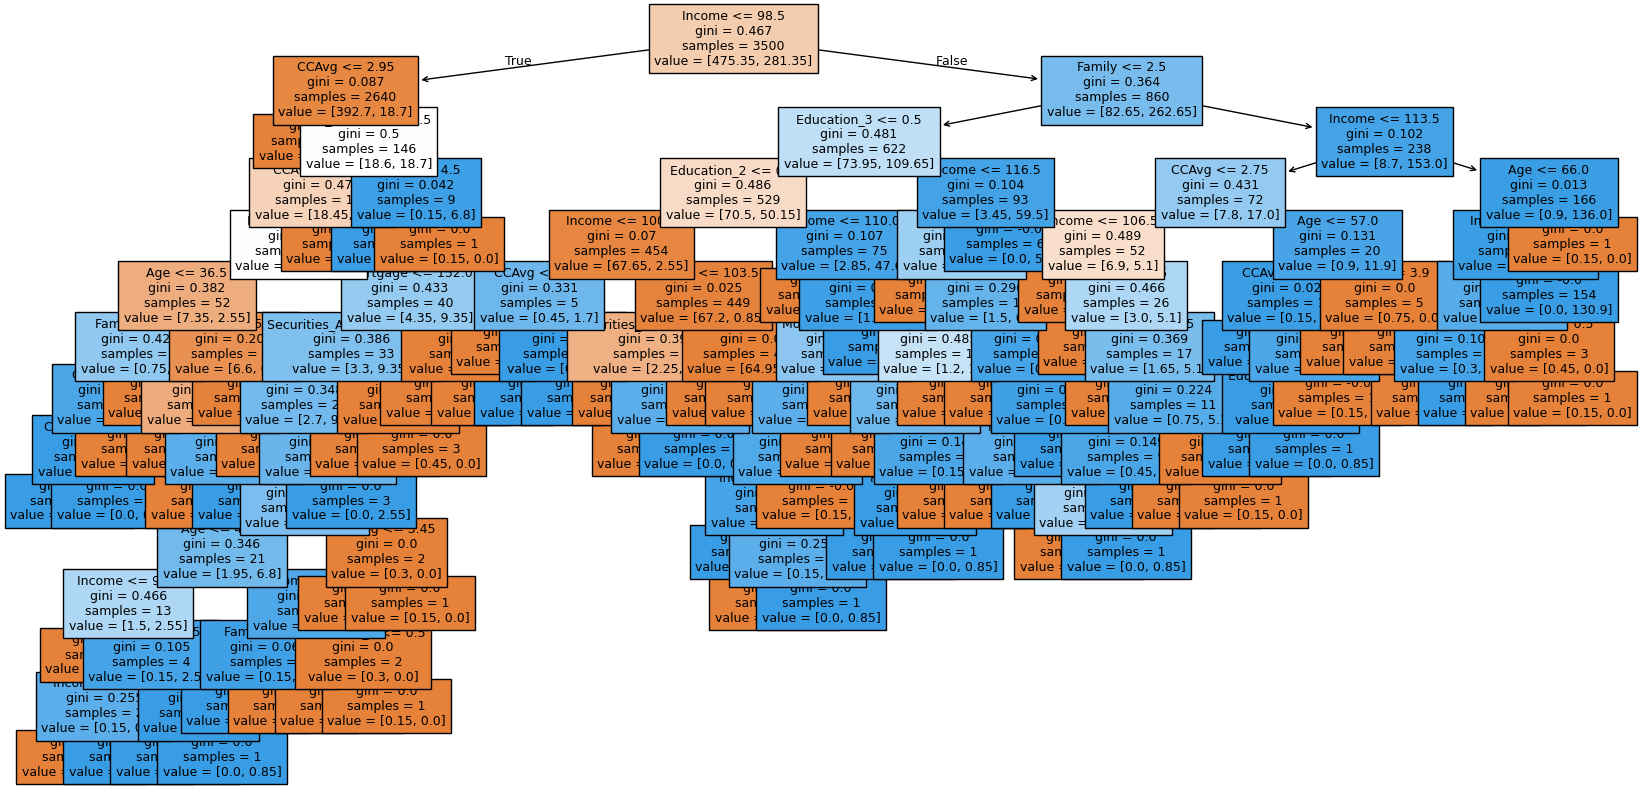

In [ ]:
#Visualization of the tree
plt.figure(figsize=(20, 10))
out = tree.plot_tree(
    estimator_2,
    feature_names=feature_names,
    filled=True,
    fontsize=9,
    node_ids=False,
    class_names=None,
)
# below code will add arrows to the decision tree split if they are missing
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor("black")
        arrow.set_linewidth(1)
plt.show()

In [ ]:
# Text report showing the rules of a decision tree -

print(tree.export_text(estimator_2, feature_names=feature_names, show_weights=True))

|--- Income <= 98.50
|   |--- CCAvg <= 2.95
|   |   |--- weights: [374.10, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- CD_Account <= 0.50
|   |   |   |--- CCAvg <= 3.95
|   |   |   |   |--- Income <= 81.50
|   |   |   |   |   |--- Age <= 36.50
|   |   |   |   |   |   |--- Family <= 3.50
|   |   |   |   |   |   |   |--- CCAvg <= 3.50
|   |   |   |   |   |   |   |   |--- CCAvg <= 3.25
|   |   |   |   |   |   |   |   |   |--- weights: [0.00, 0.85] class: 1
|   |   |   |   |   |   |   |   |--- CCAvg >  3.25
|   |   |   |   |   |   |   |   |   |--- weights: [0.00, 0.85] class: 1
|   |   |   |   |   |   |   |--- CCAvg >  3.50
|   |   |   |   |   |   |   |   |--- weights: [0.15, 0.00] class: 0
|   |   |   |   |   |   |--- Family >  3.50
|   |   |   |   |   |   |   |--- weights: [0.60, 0.00] class: 0
|   |   |   |   |   |--- Age >  36.50
|   |   |   |   |   |   |--- Age <= 45.50
|   |   |   |   |   |   |   |--- Age <= 43.50
|   |   |   |   |   |   |   |   |--- weights: [2.40, 0.00] clas

In [ ]:
#Importance of features in the tree building

print(
    pd.DataFrame(
        estimator_2.feature_importances_, columns=["Imp"], index=X_train.columns
    ).sort_values(by="Imp", ascending=False)
)

                             Imp
Income              6.010118e-01
Education_2         1.366862e-01
CCAvg               8.119895e-02
Education_3         6.729348e-02
Family              6.630288e-02
Age                 2.406181e-02
CD_Account          1.099955e-02
Mortgage            5.040802e-03
Securities_Account  4.716203e-03
Online              2.688312e-03
CreditCard          1.601820e-18


In [ ]:
importances = estimator_2.feature_importances_
indices = np.argsort(importances)

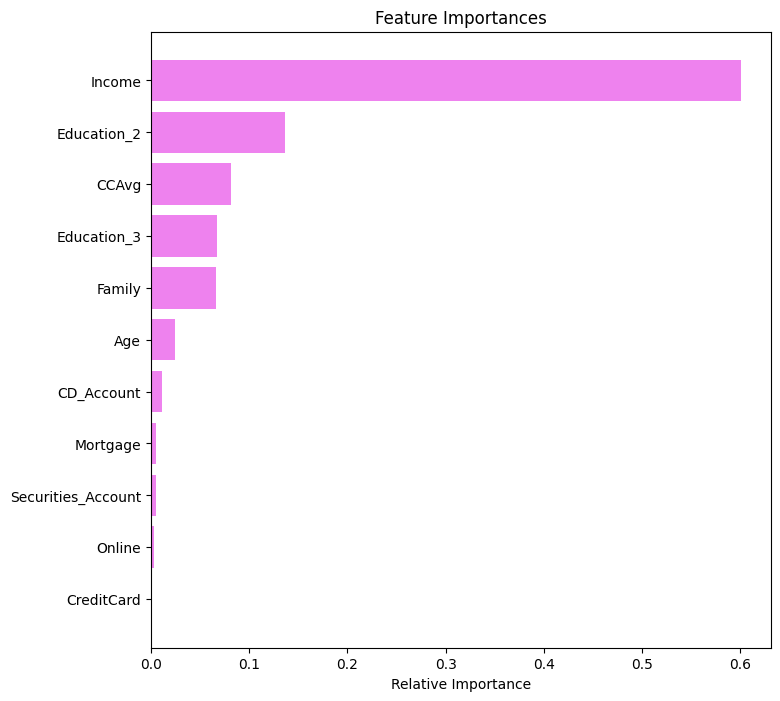

In [ ]:
plt.figure(figsize=(8, 8))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

Observations:
*  In this tree, the income, the education level, the average spending on credit cards per month (in thousand dollars) and the number of family members are the  most important features in the acceptance of loans.
* Nodes drop sharply as alpha increases.
* Post-pruning reduces the complexity and produces simpler and smaller trees.
* The best test recall is at alpha = 0
* The original (unpruned) tree already performs optimally in terms of recall.
* There is no benefit from pruning for this dataset.
* Income, Education and Spending are the strongest predictors.

## Model Performance Comparison and Final Model Selection

In [ ]:
#Comparing the models and selecting the final model
# training performance comparison

models_train_comp_df = pd.concat(
    [decision_tree_perf_train.T,
     decision_tree_tune_perf_train.T,
     decision_tree_tune_post_train.T], axis=1,
)
models_train_comp_df.columns = ["Decision Tree (sklearn default)",
                                "Decision Tree (Pre-Pruning)",
                                "Decision Tree (Post-Pruning)"]
print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,Decision Tree (sklearn default),Decision Tree (Pre-Pruning),Decision Tree (Post-Pruning)
Accuracy,1.0,0.790286,1.0
Recall,1.0,1.000000,1.0
Precision,1.0,0.310798,1.0
F1,1.0,0.474212,1.0


In [ ]:
# testing performance comparison

models_test_comp_df = pd.concat(
    [decision_tree_perf_test.T,
     decision_tree_tune_perf_test.T,
     decision_tree_tune_post_test.T], axis=1,
)
models_test_comp_df.columns = ["Decision Tree (sklearn default)",
                               "Decision Tree (Pre-Pruning)",
                               "Decision Tree (Post-Pruning)"]
print("Test set performance comparison:")
models_test_comp_df

Test set performance comparison:


,Decision Tree (sklearn default),Decision Tree (Pre-Pruning),Decision Tree (Post-Pruning)
Accuracy,0.986667,0.790286,0.979333
Recall,0.912752,1.000000,0.859060
Precision,0.951049,0.310798,0.927536
F1,0.931507,0.474212,0.891986


Observations:
* Since the most important problem that needs to be solved is that the bank wants to find customers who will accept the loan, recall is very important.
* However, precision matters too so that there won´t be too many false positives.
* The default decision tree seems to be the best model because it gives a high recall, a high precision and the highest F1.
* The pre-pruned tree allows too many false positives and the post-pruned tree allows more false negatives than the other two.

## Actionable Insights and Business Recommendations


* What recommedations would you suggest to the bank?

* Since income had the strongest correlation to personal loan, the bank could target high-income customers through marketing campaigns offering benefits like higher loan limits or personalized offers.
* Do not prioritize age-based targeting in personal loaning since they showed almost no relationship.
* Focus on costumers with a higher education since there is a higher loan acceptance in these customers.
* Implement the model to predict which customers are likely to accept loans, sending offers only to high probability customers. This will help reduce marketing costs.
* Missing a customer could be just as bad a targeting the wrong customer and wasting costs on them, so it is important to tune the model based on the business goal.
* Collecting additional data could improve model robustness and capture more diverse customer behaviors.
* Customers with higher spending are more likely to accept loans, so use spending behavior for segmentation.
* Customers with CD accounts or strong financial activity, so they are more likely to accept loan offers.
* Prioritize identifying loan-takers.
* Customer behavior changes over time, so the model should be kept updated.
* Spending and financial activity matter more.
* Concentrated customer regions exist, so it could be beneficial to run region-specific campaigns.
* The bank should adopt a data-driven targeting strategy that prioritizes financially active customers, particularly those with high income and high credit card spending. By leveraging predictive modeling and focusing on behavioral indicators rather than demographic factors, the bank can significantly improve the efficiency and effectiveness of its loan marketing campaigns.

___